# Setup

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from src.constants import DATASETS_DIR
from src.data_loading import load_csv_data, parse_preprocessing_config
from src.dataset_config import load_dataset_config
from src.preprocessing import filter_doublets, normalize_by_library_size, log_transform, normalize_with_pearson
from src.preprocessing.gene_annotation import load_gene_annotation
from src.preprocessing.gene_sets import duplicated_genes, matching_genes, rrna_genes, unmatched_genes
from src.preprocessing.pipeline import run_filtering_pipeline
from src.preprocessing.qc_metrics import cell_qc_metrics
from src.visualization import (
    plot_qc_overview,
    plot_gene_set_qc,
    plot_gene_max_count_distribution,
    plot_normalization_comparison,
    plot_log_transform_comparison,
)

## Data Loading

In [3]:
from src.data_loading import load_csv_data

DATA_PATH = DATASETS_DIR / 'E-MTAB-2805' / 'interim' / 'counts.csv.gz'
raw_data = load_csv_data(DATA_PATH)

raw_data

,ENSMUSG00000000001,ENSMUSG00000000003,ENSMUSG00000000028,ENSMUSG00000000031,ENSMUSG00000000037,ENSMUSG00000000049,ENSMUSG00000000056,ENSMUSG00000000058,ENSMUSG00000000078,ENSMUSG00000000085,...,ENSMUSG00000097926,ENSMUSG00000097927,ENSMUSG00000097928,ENSMUSG00000097929,ENSMUSG00000097930,ENSMUSG00000097931,ENSMUSG00000097932,ENSMUSG00000097933,ENSMUSG00000097934,ENSMUSG00000097935
cell_id,,,,,,,,,,,,,,,,,,,,,
G1_cell1,43,0,89,65,1,0,0,0,3,2,...,0,0,0,0,0,0,0,0,0,1
G1_cell2,82,0,598,0,0,0,19,0,514,11,...,0,0,0,0,0,0,0,0,0,0
G1_cell3,5,0,10,0,0,0,0,0,1,0,...,2,0,0,0,1,0,0,0,0,0
G1_cell4,0,0,249,0,0,0,15,0,154,0,...,0,0,0,0,223,0,0,0,0,0
G1_cell5,2,0,135,0,0,0,0,0,8,0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
G2M_cell92,331,0,164,0,42,0,0,0,172,0,...,0,0,0,0,0,0,0,0,0,2
G2M_cell93,71,0,361,0,3,0,57,0,102,0,...,0,0,0,0,42,0,0,0,0,1
G2M_cell94,1,0,199,0,0,0,138,0,1,0,...,0,0,0,0,0,0,0,0,0,0


## Dataset config

In [4]:
DATASET_DIR = DATASETS_DIR / 'E-MTAB-2805'

dataset_config = load_dataset_config(DATASET_DIR / 'config.yaml')
SPECIES = dataset_config["species"]
preprocessing_config = parse_preprocessing_config(dataset_config)

preprocessing_config

PreprocessingConfig(mito_threshold=0.2, min_gene_max_count=2, count_threshold=100000.0, gene_threshold=2000)

# Quality Control

In [5]:
qc_metrics = cell_qc_metrics(raw_data, species=SPECIES)

print(qc_metrics.median().round(3))
display(qc_metrics.head(5).round(3))
display(qc_metrics.tail(5).round(3))

count_depth           2671027.000
n_genes                 10157.000
mito_fraction               0.036
rrna_fraction               0.009
apoptosis_fraction          0.012
dtype: float64


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
S_cell57,7252713,11439,0.036,0.010,0.011
S_cell17,6687903,12043,0.076,0.023,0.012
G2M_cell7,6581735,11873,0.048,0.012,0.014
G2M_cell58,6520921,11355,0.028,0.006,0.014
G2M_cell18,6414313,10867,0.031,0.010,0.014


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
S_cell31,104,100,0.029,0.019,0.000
S_cell18,94,91,0.032,0.000,0.011
S_cell1,91,84,0.022,0.000,0.000
S_cell71,64,63,0.031,0.000,0.047
S_cell84,21,21,0.000,0.000,0.048


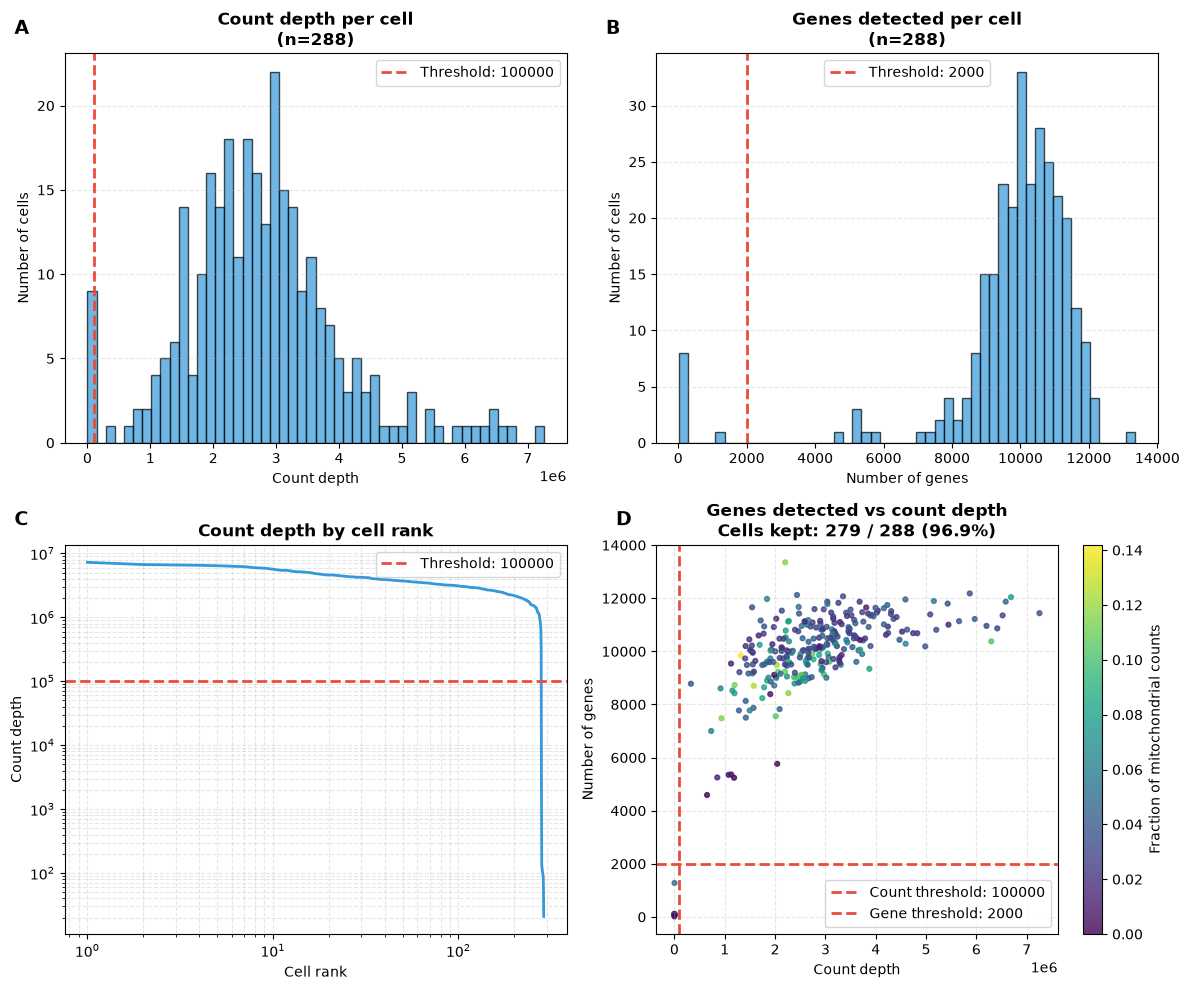

In [6]:
plot_qc_overview(
    raw_data,
    species=SPECIES,
    count_threshold=preprocessing_config.count_threshold,  # minimum count depth, set in the dataset config
    gene_threshold=preprocessing_config.gene_threshold,    # minimum genes per cell, set in the dataset config
)

## Mitochondrial, rRNA and apoptosis fractions

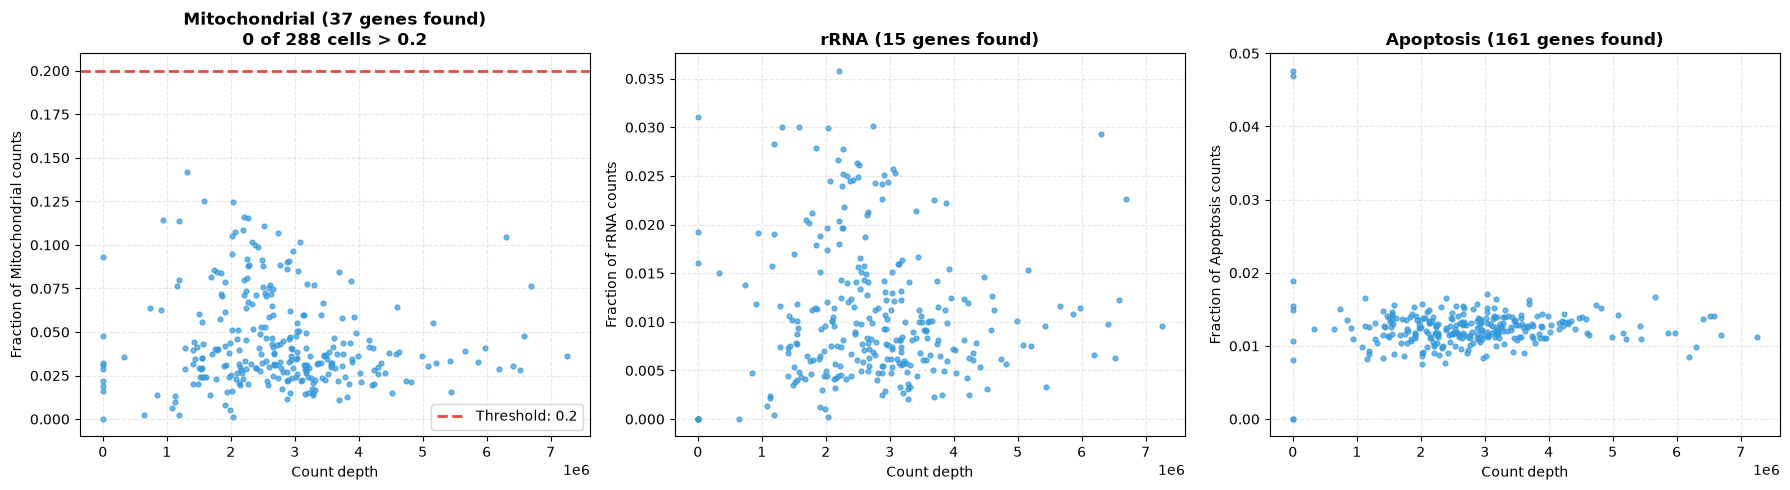

In [15]:
plot_gene_set_qc(raw_data, SPECIES, preprocessing_config)

## Genes

### Uniqueness

In [16]:
duplicates = duplicated_genes(raw_data)

print(f"Gene columns: {raw_data.shape[1]}, unique gene names: {raw_data.columns.nunique()}")
print(f"Gene names appearing in more than one column: {len(duplicates)}")
display(duplicates)

assert duplicates.empty, "Duplicated gene names found, see the table above"

Gene columns: 38293, unique gene names: 38293
Gene names appearing in more than one column: 0


,n_columns,identical_counts
gene,,


### Missing from the annotation

In [17]:
annotation = load_gene_annotation(SPECIES)
unmatched = unmatched_genes(raw_data, annotation)
alias_hits = unmatched.alias_matches
n_alias_genes = alias_hits["gene"].nunique()
n_ambiguous = alias_hits.loc[alias_hits["n_matches"] > 1, "gene"].nunique()

print(f"Genes matching no gene_id or gene_name: {n_alias_genes + len(unmatched.unknown_ensembl_ids) + len(unmatched.other)} / {raw_data.shape[1]}")
print(f"  found through alias_names: {n_alias_genes} ({n_ambiguous} matching more than one annotation row)")
print(f"  Ensembl IDs missing from the annotation: {len(unmatched.unknown_ensembl_ids)}, e.g. {unmatched.unknown_ensembl_ids[:5]}")
print(f"  other: {len(unmatched.other)}, e.g. {unmatched.other[:5]}")
display(alias_hits)

Genes matching no gene_id or gene_name: 4935 / 38293
  found through alias_names: 0 (0 matching more than one annotation row)
  Ensembl IDs missing from the annotation: 4935, e.g. ['ENSMUSG00000000325', 'ENSMUSG00000001379', 'ENSMUSG00000001417', 'ENSMUSG00000003178', 'ENSMUSG00000004613']
  other: 0, e.g. []


,gene,n_matches,gene_id,gene_name,gene_biotype,chromosome,MT_status,RB_status,TF_status,APOPT_status,alias_names


### rRNA

In [18]:
# Same matching as filter_rrna_genes, so these are exactly the columns the pipeline drops
rrna_columns = matching_genes(raw_data, rrna_genes(SPECIES, annotation))
rrna_counts = raw_data[rrna_columns].sum().sort_values(ascending=False).rename("total_counts")

print(f"rRNA genes filtered out: {len(rrna_columns)} / {raw_data.shape[1]}")
print(f"  share of all counts: {rrna_counts.sum() / raw_data.values.sum():.3f}")
display(rrna_counts.to_frame())

rRNA genes filtered out: 15 / 38293
  share of all counts: 0.011


,total_counts
ENSMUSG00000064339,7622658
ENSMUSG00000064337,883808
ENSMUSG00000064857,966
ENSMUSG00000065387,190
ENSMUSG00000070225,119
ENSMUSG00000064515,105
ENSMUSG00000075874,84
ENSMUSG00000065107,47
ENSMUSG00000064748,46
ENSMUSG00000064906,25


## Filtering pipeline

In [19]:
clean_data = run_filtering_pipeline(raw_data, config=preprocessing_config, species=SPECIES)

clean_data.shape

(279, 24928)

### Low expression genes

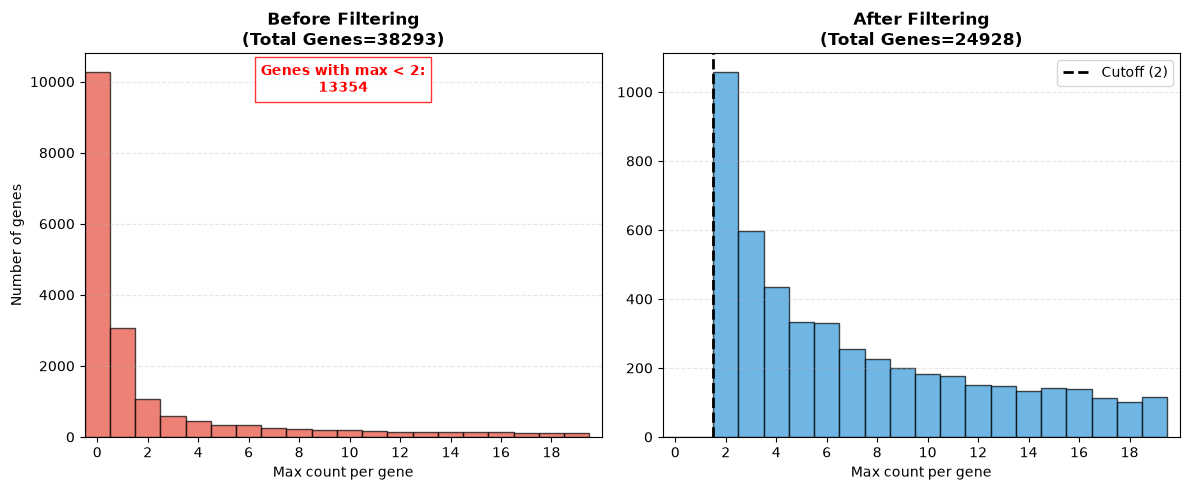

In [20]:
plot_gene_max_count_distribution(raw_data, clean_data, x_limit=20)

## Doublets (demonstration only)

We run the doublet filter to show how many cells it would remove, but the rest of the notebook continues from `clean_data`.

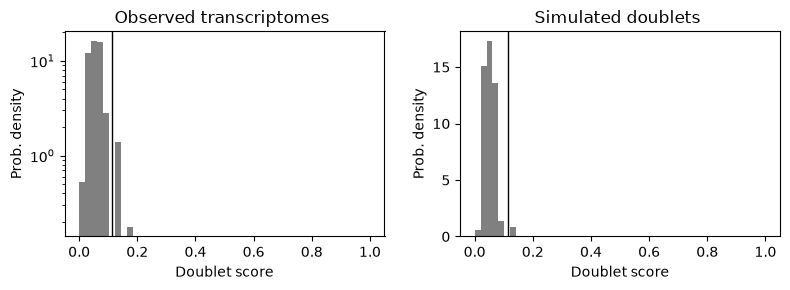

Cells removed as doublets: 9 / 279


In [21]:
# For demonstration only: the rest of the notebook continues from clean_data, not from no_doublets_data
no_doublets_data = filter_doublets(clean_data)

print(f"Cells removed as doublets: {clean_data.shape[0] - no_doublets_data.shape[0]} / {clean_data.shape[0]}")

# Normalization

## logCPM

### Normalize by library size

In [22]:
normalized_data = normalize_by_library_size(clean_data)

normalized_data.shape

(279, 24928)

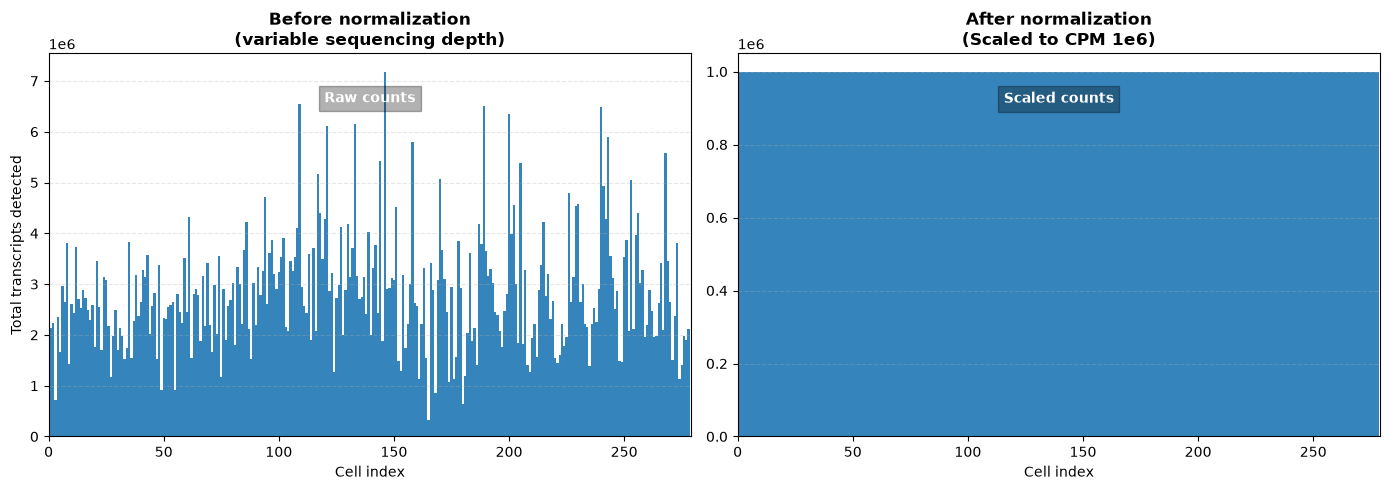

In [23]:
plot_normalization_comparison(clean_data, normalized_data, n_cells=normalized_data.shape[0])

### Log Transform

In [24]:
logged_data = log_transform(normalized_data)

logged_data.shape

(279, 24928)

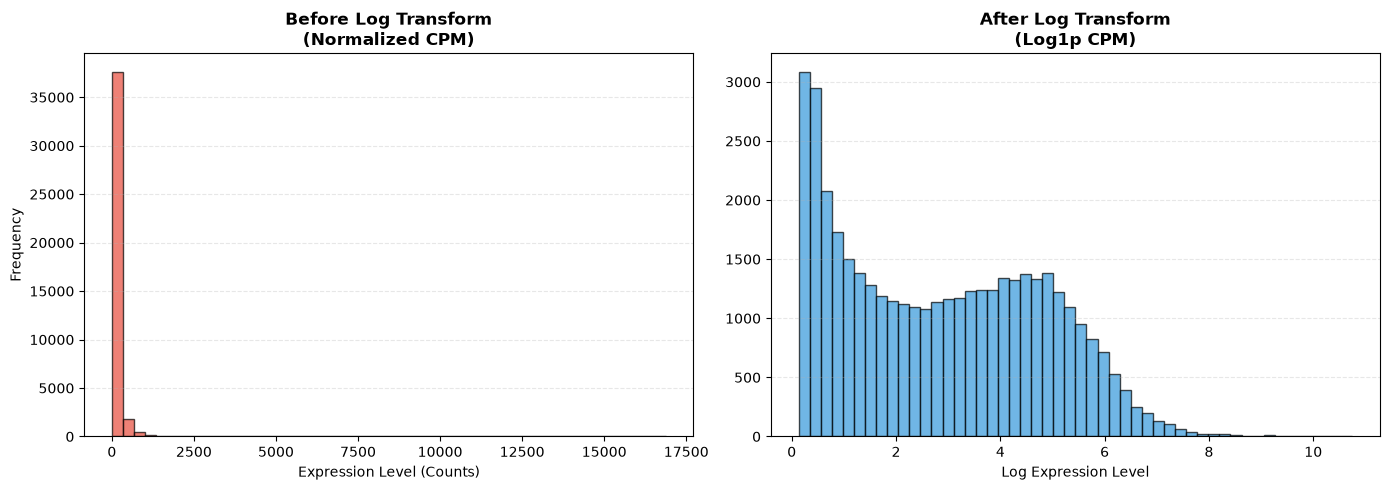

In [25]:
plot_log_transform_comparison(normalized_data, logged_data)

## Pearson residuals

In [26]:
pearsons_data = normalize_with_pearson(clean_data)

pearsons_data.shape

(279, 24928)

In [27]:
pearsons_data.head()

,ENSMUSG00000000001,ENSMUSG00000000003,ENSMUSG00000000028,ENSMUSG00000000031,ENSMUSG00000000037,ENSMUSG00000000056,ENSMUSG00000000058,ENSMUSG00000000078,ENSMUSG00000000085,ENSMUSG00000000088,...,ENSMUSG00000097921,ENSMUSG00000097922,ENSMUSG00000097923,ENSMUSG00000097924,ENSMUSG00000097925,ENSMUSG00000097926,ENSMUSG00000097928,ENSMUSG00000097929,ENSMUSG00000097930,ENSMUSG00000097935
cell_id,,,,,,,,,,,,,,,,,,,,,
G1_cell1,-7.108353,-0.067368,-5.984784,16.703293,-5.720377,-5.636285,-0.260834,-7.073629,-5.043317,6.977568,...,-0.322927,-0.438776,-0.603355,-0.157977,-0.428347,-0.453967,-0.356262,-1.958692,-4.788474,-0.162872
G1_cell2,-6.421542,-0.073637,6.360822,-2.500561,-6.174924,-3.936465,-0.285085,16.703293,-4.331115,8.833862,...,-0.352938,-0.479513,-0.659262,-0.172672,-0.468120,-0.496108,-0.389364,-2.132991,-5.120939,-1.177986
G1_cell3,-8.614563,-0.075218,-8.608535,-2.550817,-6.255993,-6.060141,-0.291204,-7.578561,-5.736266,7.281703,...,-0.360511,-0.489789,-0.673360,-0.176380,-0.478153,3.429937,-0.397715,-2.176662,-5.061173,-1.202929
G1_cell4,-7.160889,-0.042724,8.295112,-1.481860,-4.145010,-0.789975,-0.165448,13.480695,-3.695971,-2.699265,...,-0.204856,-0.278421,-0.383050,-0.100193,-0.271796,-0.288072,-0.226019,-1.256649,16.703293,-0.686623
G1_cell5,-8.752992,-0.077315,-5.764705,-2.617112,-6.360406,-6.165400,-0.299314,-7.301219,-5.842082,9.126273,...,-0.370546,-0.503408,-0.692041,-0.181295,-0.491450,-0.520826,-0.408783,-2.234346,-5.305984,-0.439223
